# Walkthrough of the demo results

**Assumption: `demo_experiment` has already run successfully, including plotting.**
This notebook opens the saved results for **seed 42**; it does not generate prices,
run strategies, or rerun CSCV. If you used another experiment or seed, change the
settings in the first code cell.

We compare the same monthly trading rules on **no-signal** and **seasonal-signal**
price series. 

## 1. Load the saved experiment

In [9]:
import json
from math import comb

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from backtest_overfitting import paths

EXPERIMENT = "demo_experiment"
SEED = 42
SCENARIOS = ("no_signal", "seasonal")
LABELS = {"no_signal": "No signal", "seasonal": "Seasonal signal"}

result_dir = paths.result_dir(EXPERIMENT, SEED)
tables_dir = paths.tables_dir(EXPERIMENT, SEED)
figures_dir = paths.figures_dir(EXPERIMENT, SEED)
metadata_path = result_dir / "experiment.json"


metadata = json.loads(metadata_path.read_text())
summary = pd.concat(
    {name: pd.read_csv(tables_dir / name / "sharpe" / "summary.csv")
     for name in SCENARIOS}
).droplevel(1)
summary.index.name = "scenario"
cscv = {
    name: pd.read_parquet(tables_dir / name / "sharpe" / "cscv.parquet")
    for name in SCENARIOS
}

## 2. Compare the headline results

**PBO** is the fraction of splits where the training winner ranks below the testing
median. **Negative OOS Sharpe** is the fraction where that winner's testing Sharpe
is below zero. They answer different questions: relative ranking versus negative
performance. Lower values are preferable for both measures.

In [10]:
overview = summary[["pbo", "probability_of_loss", "n_strategies", "n_excluded_strategies"]].rename(
    index=LABELS,
    columns={"pbo": "PBO", "probability_of_loss": "Negative OOS Sharpe",
             "n_strategies": "Eligible strategies", "n_excluded_strategies": "Excluded strategies"},
)
display(overview.style.format({"PBO": "{:.2%}", "Negative OOS Sharpe": "{:.2%}"}))

,PBO,Negative OOS Sharpe,Eligible strategies,Excluded strategies
scenario,,,,
No signal,70.24%,68.25%,7600,0
Seasonal signal,5.16%,5.56%,7600,0


## 3. Inspect the best full-sample backtests

The table shows each scenario's highest full-sample Sharpe strategy. The saved
charts show its cumulative trading P&L and the underlying price series.

These are retrospective winners selected using the whole sample. Their attractive
backtests alone do not establish that selecting them would work out of sample.
CSCV makes a separate selection inside each training split.

,strategy_id,sharpe,entry_day,holding_period,stop_loss,side
scenario,,,,,,
No signal,3319,1.088,8,3,-1,1
Seasonal signal,239,1.879,1,10,-1,1


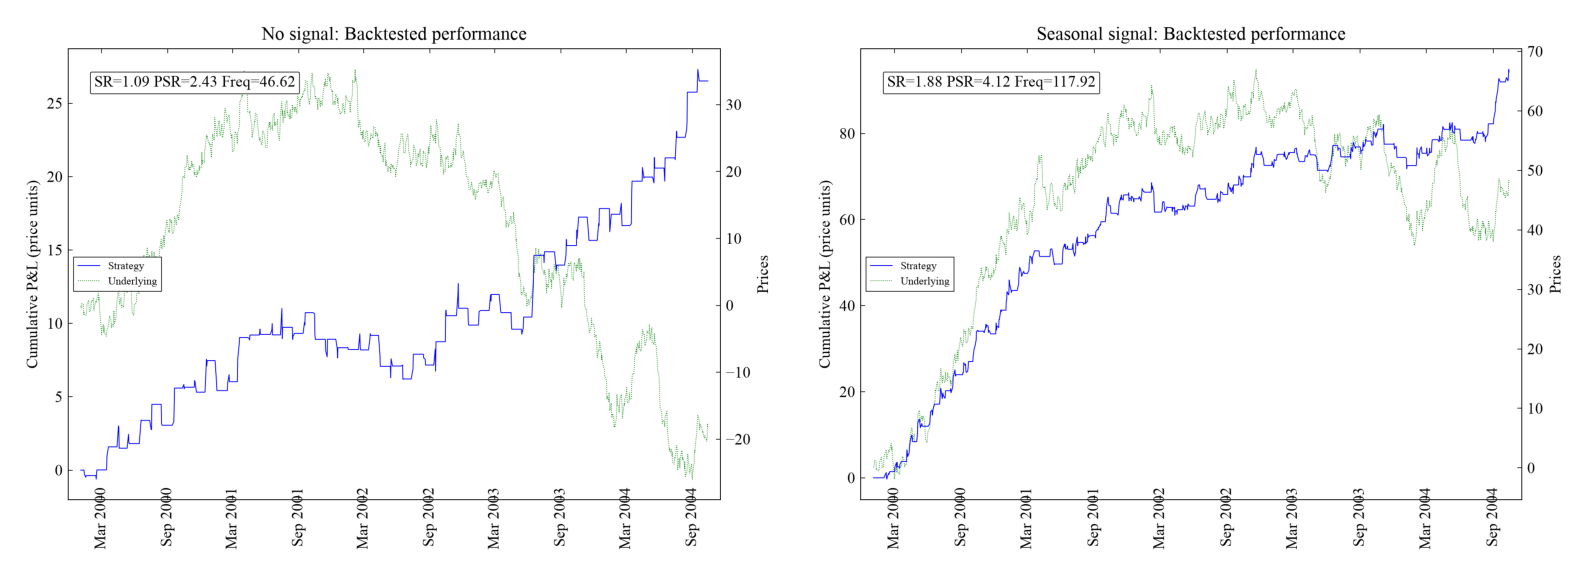

In [11]:
best_rows = []
for name in SCENARIOS:
    performance = pd.read_parquet(tables_dir / name / "sharpe" / "performance.parquet")
    best = performance.loc[performance["sharpe"].idxmax()].to_dict()
    best["scenario"] = LABELS[name]
    best_rows.append(best)

best_strategies = pd.DataFrame(best_rows).set_index("scenario")
for column in ("strategy_id", "entry_day", "holding_period", "stop_loss", "side"):
    best_strategies[column] = best_strategies[column].astype(int)
display(best_strategies.style.format({"sharpe": "{:.3f}"}))

# Show the existing PNGs; no strategy or statistical calculations are repeated.
def show_saved_figures(kind):
    files = [figures_dir / f"{name}_{kind}.png" for name in SCENARIOS]
    for file in files:
        if not file.is_file():
            raise FileNotFoundError(f"Missing saved figure: {file}. Complete the plotting step first.")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, file in zip(axes, files):
        ax.imshow(plt.imread(file))
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

show_saved_figures("backtest")

## 4. Training versus testing performance

Each point is one CSCV split: the selected strategy's training Sharpe is on the
horizontal axis and its testing Sharpe is on the vertical axis. A negative fitted
slope means higher training scores are associated with lower testing scores
across these selections. It is not, by itself, a measure of PBO.

The table reports the saved regression slope, intercept, and ordinary R².
The figure annotation uses adjusted R². Splits overlap, so the points are not
independent experiments.

,Slope,Intercept,R²
scenario,,,
No signal,-0.672,0.897,0.116
Seasonal signal,-0.636,2.468,0.214


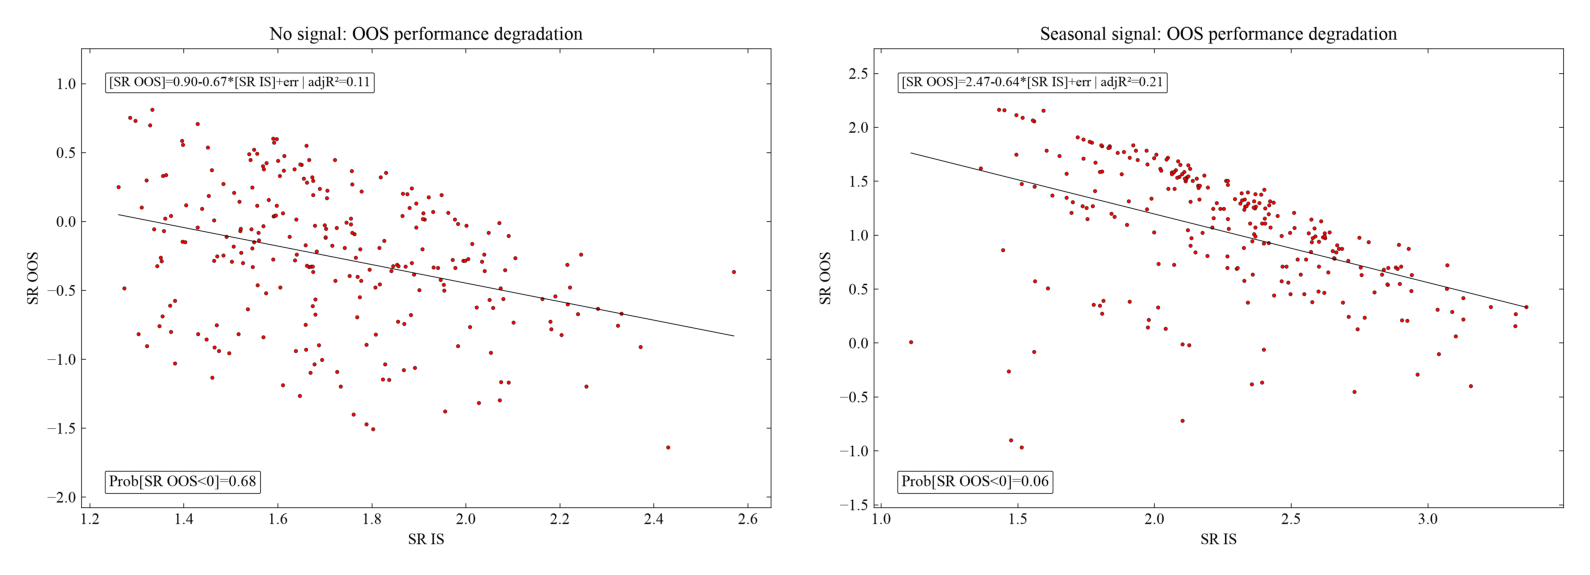

In [12]:
degradation = summary[["degradation_slope", "degradation_intercept", "degradation_r2"]].rename(
    index=LABELS,
    columns={"degradation_slope": "Slope", "degradation_intercept": "Intercept",
             "degradation_r2": "R²"},
)
display(degradation.style.format("{:.3f}"))
show_saved_figures("degradation")

## 5. Why the PBO values differ

A negative rank logit means the training winner ranks below the testing median;
a positive logit means it ranks above it. Zero logits are not counted as overfit.
The histograms show how often each case occurs.

The table below counts the saved split records directly, making the PBO reported
above easy to interpret.

,Splits,Below median,Zero logit,Above median,PBO
Scenario,,,,,
No signal,252,177,0,75,70.24%
Seasonal signal,252,13,0,239,5.16%


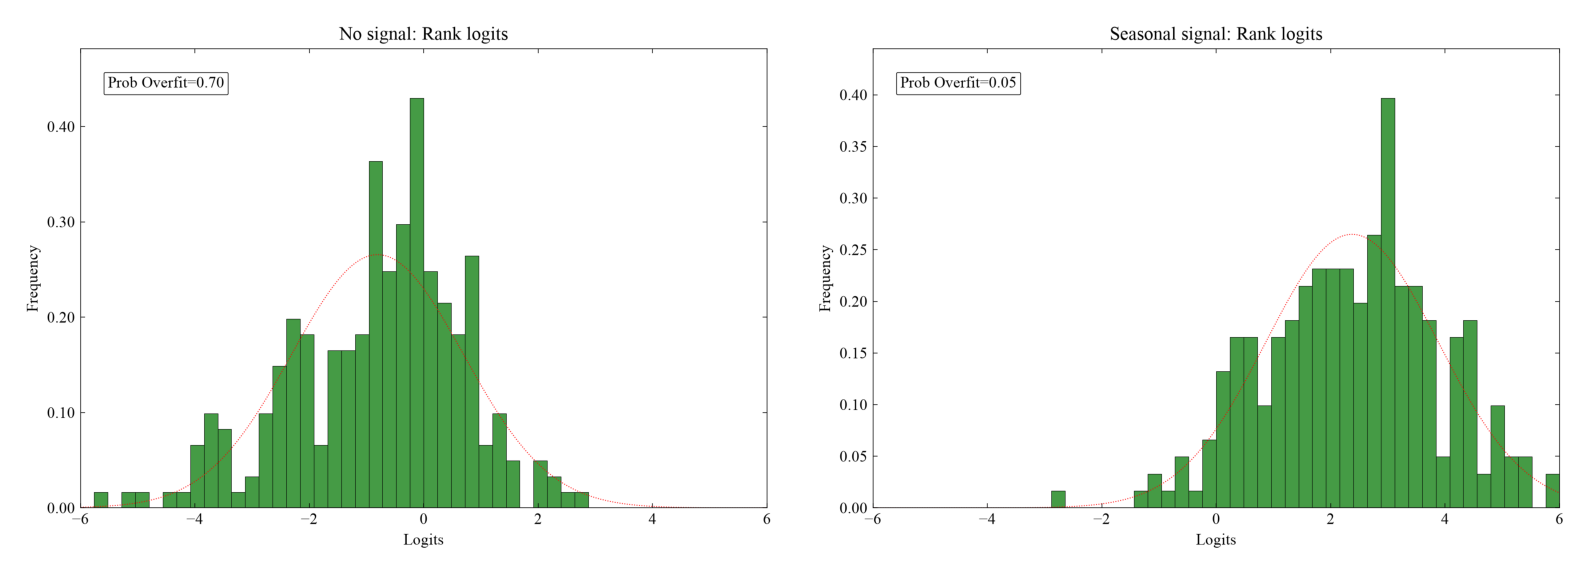

In [13]:
rank_counts = pd.DataFrame([
    {"Scenario": LABELS[name], "Splits": len(frame),
     "Below median": int((frame["logit"] < 0).sum()),
     "Zero logit": int((frame["logit"] == 0).sum()),
     "Above median": int((frame["logit"] > 0).sum()),
     "PBO": float((frame["logit"] < 0).mean())}
    for name, frame in cscv.items()
]).set_index("Scenario")
display(rank_counts.style.format({"PBO": "{:.2%}"}))
show_saved_figures("logits")

## 6. Compare the testing distributions

The blue CDF represents the training winners' testing Sharpe scores. The red CDF
pools every eligible strategy's score in every testing split. At a given Sharpe,
a lower CDF means a smaller fraction of scores falls below that level.

The green curve summarizes the integrated difference between the CDFs. A broad
rightward shift can coexist with a small crossing in the tails: first-order
dominance requires the ordering everywhere, while second-order dominance uses
the integrated difference.

**Use the pooled dominance table below to interpret these figures.** The
`vs_split_mean` fields in the scenario `summary.csv` files use a different
benchmark—the mean strategy score per split—and can give different answers.

,Selected scores,Pooled scores,First-order dominance,Second-order dominance
scenario,,,,
No signal,252,1915200,False,False
Seasonal signal,252,1915200,False,True


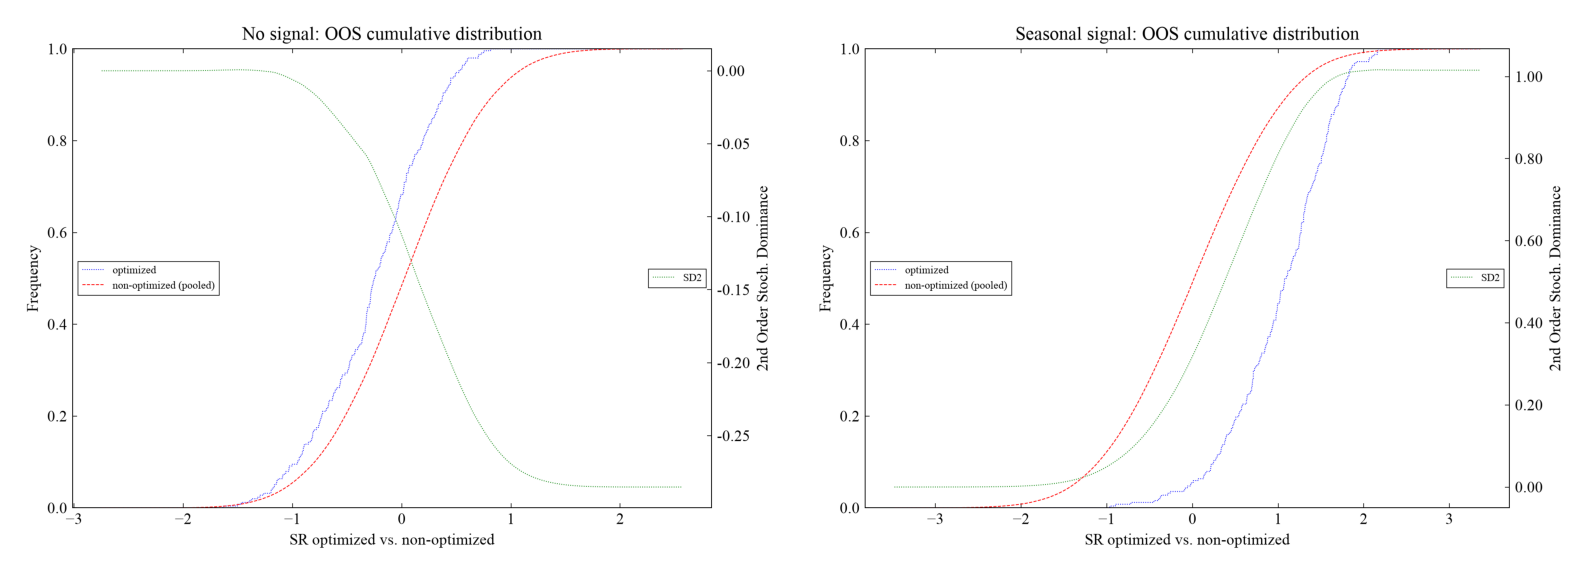

In [14]:
pooled = pd.read_csv(tables_dir / "pooled_dominance_summary.csv").set_index("scenario")
dominance = pooled[["selected_count", "benchmark_count",
                    "first_order_dominance_vs_pooled", "second_order_dominance_vs_pooled"]].rename(
    index=LABELS,
    columns={"selected_count": "Selected scores", "benchmark_count": "Pooled scores",
             "first_order_dominance_vs_pooled": "First-order dominance",
             "second_order_dominance_vs_pooled": "Second-order dominance"},
)
display(dominance)
show_saved_figures("dominance")

## 7. Check what the validation tables establish

The S table gives the number of possible splits and observations in each half.
The N table describes rank resolution for different numbers of strategies.
**These are structural diagnostics, not repeated experiments showing how PBO
changes with S or N.** The paper's binomial standard-error field is a heuristic,
not a calibrated confidence interval for overlapping splits.

The final table checks ordering, separation, coverage, and train/test symmetry
for the saved experiment. These checks do not prove that every time-series
property is preserved.

In [15]:
diagnostic_dir = tables_dir / "no_signal" / "sharpe"
effect_s = pd.read_parquet(diagnostic_dir / "validation_effect_of_S.parquet")
effect_n = pd.read_parquet(diagnostic_dir / "validation_effect_of_N.parquet")
print("Effect of S (structural counts):")
display(effect_s)
print("Effect of N (theoretical rank resolution):")
display(effect_n)

checks = ["is_chronological", "oos_chronological", "no_overlap",
          "complete_split", "equal_sample_size", "oos_reused_as_is"]
validation = {}
for name in SCENARIOS:
    table = pd.read_parquet(tables_dir / name / "sharpe" / "validation_temporal_dependence.parquet")
    validation[LABELS[name]] = table[checks].all()
display(pd.DataFrame(validation).T)

Effect of S (structural counts):


,S,T,min_block_size,max_block_size,n_combinations,is_observations,oos_observations,paper_binomial_se_upper_bound
0,4,1000,250,250,6,500,500,0.204124
1,8,1000,125,125,70,500,500,0.059761
2,10,1000,100,100,252,500,500,0.031497


Effect of N (theoretical rank resolution):


,N,columns,rank_resolution,min_logit,max_logit,unique_logit_values
0,10,10,0.090909,-2.302585,2.302585,10
1,50,50,0.019608,-3.912023,3.912023,50
2,100,100,0.009901,-4.605170,4.605170,100
3,500,500,0.001996,-6.214608,6.214608,500
4,1000,1000,0.000999,-6.907755,6.907755,1000
5,7600,7600,0.000132,-8.935904,8.935904,7600


,is_chronological,oos_chronological,no_overlap,complete_split,equal_sample_size,oos_reused_as_is
No signal,True,True,True,True,True,True
Seasonal signal,True,True,True,True,True,True


## 8. Takeaways and where to look next

Read the results together: backtest performance, testing rank, negative testing
Sharpe, and dominance each describe a different aspect of selection quality.
The following recap is calculated from the loaded summaries, so it follows the
experiment and seed selected at the top.

In [16]:
for name in SCENARIOS:
    row = summary.loc[name]
    print(f"{LABELS[name]}: PBO {row['pbo']:.2%}; "
          f"negative OOS Sharpe {row['probability_of_loss']:.2%}; "
          f"second-order dominance vs pooled strategies: "
          f"{pooled.loc[name, 'second_order_dominance_vs_pooled']}.")

gap = 100 * (summary.loc["no_signal", "pbo"] - summary.loc["seasonal", "pbo"])
if gap >= 0:
    print(f"Seasonal PBO is {gap:.2f} percentage points lower in this realization.")
else:
    print(f"Seasonal PBO is {-gap:.2f} percentage points higher in this realization.")
print(f"Combined figure: {figures_dir / 'comparison.pdf'}")

No signal: PBO 70.24%; negative OOS Sharpe 68.25%; second-order dominance vs pooled strategies: False.
Seasonal signal: PBO 5.16%; negative OOS Sharpe 5.56%; second-order dominance vs pooled strategies: True.
Seasonal PBO is 65.08 percentage points lower in this realization.
Combined figure: /Users/jaehyeonpark/Workspace/01-projects/backtest-overfitting/results/replication/demo_experiment/seed_42/figures/comparison.pdf
